# Классификация звуков окружающей среды

Михаил Черемисин. DLS Speech, домашняя работа 1.

Решение подготовлено с помощью ИИ; вычисления выполнены, результаты и ограничения приведены ниже.

Источник: [Исходное задание DLS Speech](https://github.com/DeepLearningSchool/Speech/blob/main/week_01_speech_intro_to_audio/Homework/Homework_1_Environmental_Sound_Classification_for_students.ipynb)

Цель — научиться определять один из пяти звуков по исходному WAV, без мел-спектрограмм. Для сдачи нужны этот notebook с отчётом и submission.csv.

## 1. Данные и воспроизводимость

Публичные исходники скачиваются по ссылкам из задания. Архив около 645 МБ, извлекаются только 200 нужных записей. Уже скачанные файлы повторно не загружаются. Если рядом есть папка files с логами, результаты прогонов загружаются; в чистом Colab модели обучаются заново. Среда должна иметь доступ к Google Drive.

In [1]:
from pathlib import Path
import importlib.util, subprocess, sys
required = {'numpy':'numpy','scipy':'scipy','soundfile':'soundfile','torch':'torch','gdown':'gdown','matplotlib':'matplotlib'}
missing = [p for m,p in required.items() if importlib.util.find_spec(m) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
if (Path.cwd().parent/'files'/'data'/'train.csv').exists():
    WORK_FILES = Path.cwd().parent/'files'
else:
    WORK_FILES = Path.cwd()/'speech_hw1_work'
WORK_FILES.mkdir(exist_ok=True)
DATA = WORK_FILES/'data'
DATA.mkdir(exist_ok=True)
import gdown
data_sources = {
 'train.csv':'1BvUhnTeOvik0NeuJtMrfr7LXpHCU1DUT',
 'valid.csv':'1my0RPDQdTxvCGmnZei06tiXgKko3R4o4',
 'test.csv':'1Z6BG52Tmyjxhen7DqvO59Rlz-2pAg7ks',
 'sound_classification_dataset.zip':'1TQa-tOX1b8QxuXBcrYrTveVAwfw1XBPO'}
for name, file_id in data_sources.items():
    target=DATA/name
    if not target.exists():
        gdown.download(id=file_id, output=str(target), quiet=False, use_cookies=False)
print('Данные доступны:', ', '.join(data_sources))


Данные доступны: train.csv, valid.csv, test.csv, sound_classification_dataset.zip


## 2. Обработка WAV, модели и обучение

Частота — 16000 Гц, один канал, длина — 5 секунд (80000 отсчётов). Дополнение нулями и обрезка приводят вход к единому размеру. Исходные CSV используются без изменения разделения. Проверены отсутствие пересечений файлов и идентификаторов исходных записей.

WaveCNN получает волну напрямую. Сравниваются ширина 8, ширина 16 и ширина 16 с аугментациями (громкость, сдвиг, шум). Проверочные и итоговые записи не аугментируются. 60 эпох, AdamW, seed 42. Выбор checkpoint по accuracy valid, при равенстве — по меньшей cross-entropy. Все три эксперимента фиксируются, неудачные результаты не удаляются.

In [2]:
"""Reproducible raw-waveform experiments for DLS Speech Homework 1."""
from pathlib import Path
import sys
import csv
import json
import math
import random
import hashlib
import time
import zipfile
import copy
import os

import numpy as np
import soundfile as sf
from scipy.signal import resample_poly
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

HERE = WORK_FILES
DATA = HERE / 'data'
OUT = HERE / 'experiments'
OUT.mkdir(exist_ok=True)
torch.set_num_threads(4)
torch.set_num_interop_threads(1)
SEED = 42
SR = 16000
LENGTH = SR * 5

def read_csv(name):
    with (DATA / name).open(encoding='utf-8-sig', newline='') as handle:
        return list(csv.DictReader(handle))

rows = {split: read_csv(split + '.csv') for split in ['train', 'valid', 'test']}
classes = sorted({row['category'] for row in rows['train']})
assert len(classes) == 5
names = {s: {r['filename'] for r in rr} for s, rr in rows.items()}
assert not (names['train'] & names['valid'] or names['train'] & names['test'] or names['valid'] & names['test'])
source_ids = {s: {r['filename'].split('-')[1] for r in rr} for s, rr in rows.items()}
assert not (source_ids['train'] & source_ids['valid'] or source_ids['train'] & source_ids['test'] or source_ids['valid'] & source_ids['test'])
assert all('category' not in row for row in rows['test']), 'Hidden labels must stay hidden'

# Extract only the 200 task recordings, using safe destination names from CSV.
audio_dir = DATA / 'audio'
audio_dir.mkdir(exist_ok=True)
needed = set.union(*names.values())
with zipfile.ZipFile(DATA / 'sound_classification_dataset.zip') as archive:
    members = {Path(info.filename).name: info for info in archive.infolist() if not info.is_dir()}
    for name in sorted(needed):
        assert Path(name).name == name and name.endswith('.wav')
        dest = audio_dir / name
        if not dest.exists():
            dest.write_bytes(archive.read(members[name]))

def preprocess(wave, original_sr):
    # soundfile returns samples x channels. Average channels, resample, pad/cut.
    if wave.ndim == 2:
        wave = wave.mean(axis=1)
    if original_sr != SR:
        gcd = math.gcd(original_sr, SR)
        wave = resample_poly(wave, SR // gcd, original_sr // gcd)
    wave = np.pad(wave[:LENGTH], (0, max(0, LENGTH - len(wave))))
    return np.asarray(wave, dtype=np.float32)

def check_preprocessing():
    stereo = np.column_stack([np.ones(22050), np.zeros(22050)]).astype('float32')
    converted = preprocess(stereo, 22050)
    assert converted.shape == (LENGTH,) and np.isfinite(converted).all()
    assert abs(float(converted[100:15000].mean()) - 0.5) < 0.01
    assert np.max(np.abs(converted[17000:])) == 0
    assert preprocess(np.ones(96000), 16000).shape == (LENGTH,)

check_preprocessing()
signals = {}
audio_info = []
for name in sorted(needed):
    wave, sr = sf.read(audio_dir / name, dtype='float32', always_2d=True)
    signals[name] = torch.from_numpy(preprocess(wave, sr)).unsqueeze(0)
    audio_info.append({'filename': name, 'sample_rate': sr, 'channels': wave.shape[1], 'frames': len(wave)})

class AudioDataset(Dataset):
    def __init__(self, split, augment=False):
        self.rows = rows[split]
        self.augment = augment

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows[index]
        x = signals[row['filename']].clone()
        # Deterministic validation/test: augment training examples only.
        if self.augment:
            x *= 10 ** (random.uniform(-6, 6) / 20)
            shift = random.randint(-SR // 2, SR // 2)
            x = torch.roll(x, shift, dims=-1)
            if shift > 0:
                x[..., :shift] = 0
            elif shift < 0:
                x[..., shift:] = 0
            if random.random() < 0.5:
                rms = x.square().mean().sqrt().clamp_min(1e-5)
                snr = random.uniform(15, 30)
                x += torch.randn_like(x) * rms / (10 ** (snr / 20))
        label = classes.index(row['category']) if 'category' in row else -1
        return x, label

class WaveCNN(nn.Module):
    def __init__(self, width=16):
        super().__init__()
        layers = [nn.Conv1d(1, width, 80, stride=16, padding=32), nn.BatchNorm1d(width), nn.ReLU(), nn.MaxPool1d(4)]
        current = width
        for next_width in [width * 2, width * 4, width * 4]:
            layers += [nn.Conv1d(current, next_width, 9, padding=4), nn.BatchNorm1d(next_width), nn.ReLU(), nn.MaxPool1d(4)]
            current = next_width
        layers += [nn.AdaptiveAvgPool1d(1), nn.Flatten(), nn.Dropout(0.2), nn.Linear(current, len(classes))]
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

def seed_all():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

def evaluate(model, loader):
    model.eval()
    losses, correct, count, predictions, labels = 0.0, 0, 0, [], []
    with torch.inference_mode():
        for x, y in loader:
            scores = model(x)
            pred = scores.argmax(1)
            if (y >= 0).all():
                losses += nn.functional.cross_entropy(scores, y, reduction='sum').item()
                correct += (pred == y).sum().item()
            count += len(y)
            predictions.extend(pred.tolist())
            labels.extend(y.tolist())
    return {'loss': losses / count, 'accuracy': correct / count, 'predictions': predictions, 'labels': labels}

def run_experiment(name, width, augment, epochs=60):
    seed_all()
    train_loader = DataLoader(AudioDataset('train', augment), batch_size=16, shuffle=True)
    valid_loader = DataLoader(AudioDataset('valid'), batch_size=16, shuffle=False)
    model = WaveCNN(width)
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.001)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    history = []
    best_score, best_loss, best_epoch, best_state = -1, float('inf'), None, None
    started = time.perf_counter()
    for epoch in range(1, epochs + 1):
        model.train()
        loss_sum, correct, count = 0.0, 0, 0
        for x, y in train_loader:
            optimizer.zero_grad(set_to_none=True)
            scores = model(x)
            loss = nn.functional.cross_entropy(scores, y)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * len(y)
            correct += (scores.argmax(1) == y).sum().item()
            count += len(y)
        scheduler.step()
        valid = evaluate(model, valid_loader)
        entry = {'epoch': epoch, 'train_loss': loss_sum / count, 'train_accuracy': correct / count, 'valid_loss': valid['loss'], 'valid_accuracy': valid['accuracy']}
        history.append(entry)
        if valid['accuracy'] > best_score or (valid['accuracy'] == best_score and valid['loss'] < best_loss):
            best_score, best_loss, best_epoch = valid['accuracy'], valid['loss'], epoch
            best_state = copy.deepcopy(model.state_dict())
        if epoch % 10 == 0:
            print(name, epoch, 'train', round(correct/count, 3), 'valid', valid['accuracy'], 'best', best_score, flush=True)
    model.load_state_dict(best_state)
    validation = evaluate(model, valid_loader)
    clean_train = evaluate(model, DataLoader(AudioDataset('train'), batch_size=16))
    result = {'name': name, 'width': width, 'augment': augment, 'epochs': epochs, 'best_epoch': best_epoch, 'valid_accuracy': best_score, 'clean_train_accuracy': clean_train['accuracy'], 'elapsed_seconds': time.perf_counter()-started, 'parameters': sum(p.numel() for p in model.parameters()), 'history': history, 'validation': validation}
    torch.save({'state_dict': best_state, 'width': width, 'classes': classes, 'sample_rate': SR, 'seconds': 5, 'seed': SEED}, OUT / (name + '.pt'))
    (OUT / (name + '.json')).write_text(json.dumps(result, indent=2), encoding='utf-8')
    print('Finished', name, best_score, 'seconds', result['elapsed_seconds'], flush=True)
    return result

def main():
    results = []
    experiments = [('small_cnn', 8, False), ('wide_cnn', 16, False), ('wide_cnn_augmented', 16, True)]
    for name, width, augment in experiments:
        existing = OUT / (name + '.json')
        result = json.loads(existing.read_text(encoding='utf-8')) if existing.exists() else run_experiment(name, width, augment)
        results.append(result)
    # Select using validation only, never the hidden test labels.
    best = max(results, key=lambda r: (r['valid_accuracy'], -r['validation']['loss']))
    checkpoint = torch.load(OUT / (best['name'] + '.pt'), map_location='cpu', weights_only=True)
    model = WaveCNN(checkpoint['width'])
    model.load_state_dict(checkpoint['state_dict'])
    test_predictions = evaluate(model, DataLoader(AudioDataset('test'), batch_size=16))['predictions']
    assert len(test_predictions) == len(rows['test'])
    with (OUT / 'submission.csv').open('w', encoding='utf-8', newline='') as handle:
        writer = csv.DictWriter(handle, fieldnames=['filename', 'category'])
        writer.writeheader()
        for row, pred in zip(rows['test'], test_predictions):
            writer.writerow({'filename': row['filename'], 'category': classes[pred]})
    audit = {'classes': classes, 'split_sizes': {s:len(rr) for s,rr in rows.items()}, 'source_groups_disjoint': True, 'filenames_disjoint': True, 'test_labels_used': False, 'audio_info':audio_info, 'selected_experiment':best['name'], 'validation_accuracy':best['valid_accuracy'], 'test_accuracy': None, 'checks': {'preprocessing':True,'augmentation_train_only':True,'submission_order_preserved':True}, 'csv_sha256':{s:hashlib.sha256((DATA/(s+'.csv')).read_bytes()).hexdigest() for s in rows}}
    (OUT / 'audit.json').write_text(json.dumps(audit, indent=2), encoding='utf-8')
    print('BEST', best['name'], best['valid_accuracy'], 'TEST ACCURACY UNKNOWN', flush=True)




## 3. Реальные результаты и файл предсказаний

Train accuracy ниже — измерение сохранённых лучших весов на чистой обучающей выборке. Это не средняя accuracy во время эпохи. Правильные ответы скрытого test не использованы.

In [3]:
main()
experiment_results=[json.loads((OUT/(n+'.json')).read_text(encoding='utf-8')) for n in ['small_cnn','wide_cnn','wide_cnn_augmented']]
for e in experiment_results:
    print(f"{e['name']}: train={e['clean_train_accuracy']:.1%}; valid={e['valid_accuracy']:.1%}; эпоха={e['best_epoch']}")
audit=json.loads((OUT/'audit.json').read_text(encoding='utf-8'))
best=next(e for e in experiment_results if e['name']==audit['selected_experiment'])
print('Выбран:', best['name'], 'Верно:', round(best['valid_accuracy']*40), 'из 40')
print('Точность скрытого test неизвестна. Прогнозы:', len(rows['test']))
with (OUT/'submission.csv').open(encoding='utf-8', newline='') as f:
    submission_rows=list(csv.DictReader(f))
assert [r['filename'] for r in submission_rows] == [r['filename'] for r in rows['test']]
assert all(r['category'] in classes for r in submission_rows)
import shutil
shutil.copyfile(OUT/'submission.csv', Path.cwd()/'submission.csv')
print('Проверки формата и порядка строк пройдены. submission.csv записан рядом с notebook.')


BEST wide_cnn_augmented 0.975 TEST ACCURACY UNKNOWN


small_cnn: train=91.7%; valid=95.0%; эпоха=18
wide_cnn: train=94.2%; valid=97.5%; эпоха=24
wide_cnn_augmented: train=96.7%; valid=97.5%; эпоха=31
Выбран: wide_cnn_augmented Верно: 39 из 40
Точность скрытого test неизвестна. Прогнозы: 40
Проверки формата и порядка строк пройдены. submission.csv записан рядом с notebook.


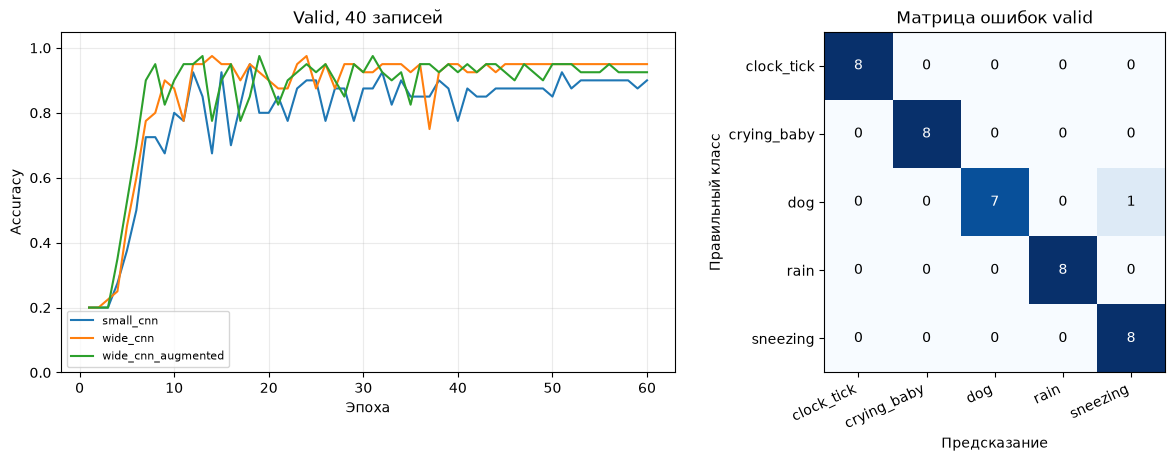

In [4]:
import matplotlib.pyplot as plt
fig,axs=plt.subplots(1,2,figsize=(13,4.5),layout='constrained')
for e in experiment_results:
    axs[0].plot([r['epoch'] for r in e['history']], [r['valid_accuracy'] for r in e['history']], label=e['name'])
axs[0].set(xlabel='Эпоха',ylabel='Accuracy',title='Valid, 40 записей',ylim=(0,1.05))
axs[0].legend(fontsize=8); axs[0].grid(alpha=.25)
matrix=np.zeros((5,5),dtype=int)
for actual,pred in zip(best['validation']['labels'],best['validation']['predictions']):matrix[actual,pred]+=1
axs[1].imshow(matrix,cmap='Blues')
axs[1].set(xticks=range(5),yticks=range(5),xticklabels=classes,yticklabels=classes,xlabel='Предсказание',ylabel='Правильный класс',title='Матрица ошибок valid')
plt.setp(axs[1].get_xticklabels(),rotation=25,ha='right')
for i in range(5):
    for j in range(5):axs[1].text(j,i,str(matrix[i,j]),ha='center',va='center',color='white' if matrix[i,j]>matrix.max()/2 else 'black')
plt.show()


## 4. Выводы и ограничения

small_cnn: train=91.7%, valid=95.0%, epoch=18, parameters=16045
wide_cnn: train=94.2%, valid=97.5%, epoch=24, parameters=62037
wide_cnn_augmented: train=96.7%, valid=97.5%, epoch=31, parameters=62037

В каждом эксперименте 60 эпох, seed 42. Эпоха — один проход по всему обучающему набору. Для каждого варианта сохранены веса лучшей эпохи по valid; при одинаковой accuracy предпочтительнее меньшая cross-entropy. Accuracy — доля верных ответов. Cross-entropy показывает, насколько модель ошибается в вероятностях классов.

Выбрана wide_cnn_augmented, эпоха 31: 39 верных ответов из 40 (97.5%). Чистая обучающая accuracy выбранных весов — 96.7%. Это отдельная оценка без случайных аугментаций; она может отличаться от показателя внутри обучающей эпохи.

Широкая сеть улучшила accuracy с 38/40 до 39/40. Аугментации не повысили число верных ответов по сравнению с широкой сетью без них (39/40 в обоих случаях), но уменьшили cross-entropy с 0,331 до 0,312. Поэтому выбран вариант с аугментациями, без заявления о доказанном преимуществе на новых данных. Единственная ошибка выбранного checkpoint — лай принят за чихание.

Ограничения
Проверочная выборка мала: одна запись изменяет accuracy на 2,5 процентного пункта. Она использована для выбора эпохи и варианта модели, поэтому итоговая оценка может быть оптимистичной. Точность на скрытой test неизвестна. Не заявляются баллы Stepik, сертификат или принятие преподавателем. Таблица результатов честно показывает и случаи, когда усложнение или аугментации не помогли.

